**Name:** Francis Reuben R  
**USN:** 1RUA25CSE0168  
**Section:** G  

# Lab 4 — Assignment


**Based on:** Lab-4-b (Bernoulli, Binomial, Poisson, Normal, Uniform)


---

### Instructions

1. Run the **Setup** cell first. Do not modify it.
2. There are **10 questions** — two on each distribution. Attempt **all** of them.
3. Every question has three parts:
   - **(a)** and **(b)** — work these out **by hand** and type your working in the *Written answer* cell.
   - **(c)** — write **Python code** in the blank code cell provided and produce the plot asked for.
4. Use `DISCRETE_COLOR` for discrete plots (bars) and `CONTINUOUS_COLOR` for continuous plots (curves).
5. Every plot must have an **x-label, y-label and a title**. Marks are deducted for unlabelled plots.
6. Round all probabilities to **4 decimal places**.
7. Save the notebook with all outputs visible before submitting.

### Marks distribution

| Section | Questions | Marks each | Total |
|---|---|---|---|
| A — Bernoulli | Q1, Q2 | 5 | 10 |
| B — Binomial | Q3, Q4 | 5 | 10 |
| C — Poisson | Q5, Q6 | 5 | 10 |
| D — Normal | Q7, Q8 | 5 | 10 |
| E — Uniform | Q9, Q10 | 5 | 10 |
| | | **Total** | **50** |

### Quick reference — which function do I need?

| Task | `scipy.stats` call |
|---|---|
| $P(X = k)$, discrete | `.pmf(k, ...)` |
| $f(x)$, continuous | `.pdf(x, ...)` |
| $P(X \le x)$ | `.cdf(x, ...)` |
| $P(X > x)$ | `.sf(x, ...)` |
| Value with given $P(X \le x)$ | `.ppf(prob, ...)` |
| Mean / variance | `.mean(...)`, `.var(...)` |
| Random samples | `.rvs(..., size=n, random_state=seed)` |

---


## Setup
Run this cell first — do not change it.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from math import comb, factorial, exp, sqrt

DISCRETE_COLOR = "#0E9F9A"     # teal   -> discrete distributions
CONTINUOUS_COLOR = "#E4572E"   # orange -> continuous distributions
HIGHLIGHT_COLOR = "#F4A261"    # use this to highlight a bar or a shaded area

plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

print("Setup complete — you are ready to start.")

Setup complete — you are ready to start.


---
# Part A — Bernoulli distribution
*Recall:* $P(X=x) = p^x(1-p)^{1-x}$ for $x \in \{0,1\}$, $\;E[X]=p$, $\;Var(X)=p(1-p)$.

## Q1. The library gate scanner 

> 📚 The RFID gate at the college library reads a student's ID card correctly on the **first tap 92%** of the time. One student taps her card once.
>
> Let $X = 1$ if the card is read on the first tap, and $X = 0$ if it is not.
>
> **(a)** State the value of $p$ and find $P(X=1)$ and $P(X=0)$.
> **(b)** Find the mean and the variance of $X$, showing the substitution into the formulas.
> **(c)** Write Python code that:
> - builds the PMF of $X$ using `stats.bernoulli.pmf`,
> - draws a **bar chart** of the distribution in `DISCRETE_COLOR` with the ticks labelled `"Not read (0)"` and `"Read (1)"`,
> - writes the probability value on top of each bar,
> - prints the mean and the variance obtained from `scipy`, and checks that they match your hand answers in (b).

#### Written answer (a) and (b)

**(a)** One tap is one Bernoulli trial. The gate reads the card on the first tap 92% of the time, so $p = 0.92$.

$$P(X=1) = p = 0.92$$

$$P(X=0) = 1-p = 0.08$$

**(b)** Substitute into the Bernoulli formulas:

$$E[X] = p = 0.92$$

$$Var(X) = p(1-p) = 0.92 \times 0.08 = 0.0736$$


P(X=0) = 0.0800
P(X=1) = 0.9200
scipy mean = 0.9200    hand mean = 0.9200    match = True
scipy var  = 0.0736    hand var  = 0.0736    match = True


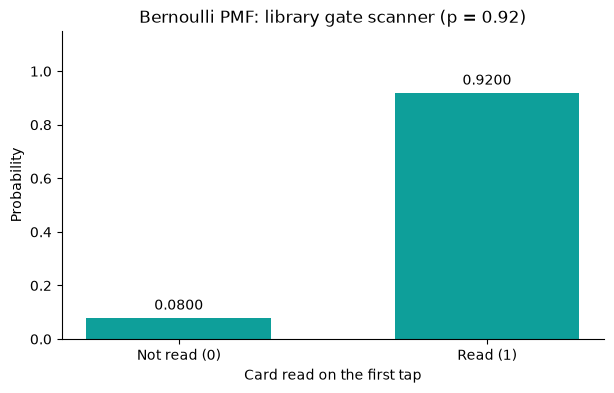

In [2]:
%matplotlib inline
# Q1. Bernoulli PMF of one library-gate tap
p = 0.92
x = np.array([0, 1])
pmf = stats.bernoulli.pmf(x, p)
mean_scipy = stats.bernoulli.mean(p)
var_scipy = stats.bernoulli.var(p)

print(f"P(X=0) = {pmf[0]:.4f}")
print(f"P(X=1) = {pmf[1]:.4f}")
print(f"scipy mean = {mean_scipy:.4f}    hand mean = 0.9200    match = {np.isclose(mean_scipy, 0.92)}")
print(f"scipy var  = {var_scipy:.4f}    hand var  = 0.0736    match = {np.isclose(var_scipy, 0.0736)}")

fig, ax = plt.subplots()
ax.bar(x, pmf, color=DISCRETE_COLOR, width=0.6)
ax.set_xticks(x, ["Not read (0)", "Read (1)"])
ax.set_xlabel("Card read on the first tap")
ax.set_ylabel("Probability")
ax.set_title("Bernoulli PMF: library gate scanner (p = 0.92)")
ax.set_ylim(0, 1.15)
for xi, pi in zip(x, pmf):
    ax.text(xi, pi + 0.03, f"{pi:.4f}", ha="center")
plt.show()


## Q2. Estimating $p$ from attendance data &nbsp;&nbsp;<sub>[5 marks] — *harder*</sub>

> 👆 A biometric attendance device records whether a student's fingerprint is accepted on the **first attempt**. Over one semester the device logged **2,000 scans**, of which **1,740** were accepted on the first attempt. Treat one scan as a single Bernoulli trial with $X=1$ for *accepted*.
>
> **(a)** Estimate $p$ from the data and write down the full PMF $P(X=x)$ with the estimated value substituted in.
> **(b)** Find the mean and variance. Then answer: for what value of $p$ would the variance of a Bernoulli variable be the **largest possible**, and what is that largest value? Justify your answer using the formula $Var(X)=p(1-p)$.
> **(c)** Write Python code that:
> - simulates 2,000 Bernoulli trials with your estimated $p$ using `stats.bernoulli.rvs(..., random_state=42)`,
> - prints the **simulated proportion** of successes next to the theoretical $p$,
> - plots the **theoretical PMF and the simulated relative frequencies side by side** as grouped bars with a legend,
> - plots $Var(X)=p(1-p)$ against $p$ for $p$ from 0 to 1 in a **second figure**, and marks the maximum point with a marker and an annotation.

#### Written answer (a) and (b)

**(a)** Estimate $p$ by the sample proportion of first-attempt accepts:

$$\hat{p} = \frac{1740}{2000} = 0.87, \qquad 1-\hat{p} = 0.13$$

$$P(X=x) = (0.87)^{x}(0.13)^{1-x}, \quad x \in \{0,1\}$$

So $P(X=1) = 0.87$ and $P(X=0) = 0.13$.

**(b)** 

$$E[X] = \hat{p} = 0.87$$

$$Var(X) = \hat{p}(1-\hat{p}) = 0.87 \times 0.13 = 0.1131$$

$Var(X) = p(1-p) = p - p^2$. The derivative is $1-2p$. Set it to zero: $p = 0.5$. The second derivative is $-2$, so this critical point is a maximum.

$$Var(X)\big|_{p=0.5} = 0.5 \times 0.5 = 0.25$$

The largest possible Bernoulli variance is $0.25$, at $p = 0.5$.


theoretical p = 0.8700
simulated proportion of successes = 0.8675
scipy mean = 0.8700    hand = 0.8700
scipy var  = 0.1131    hand = 0.1131


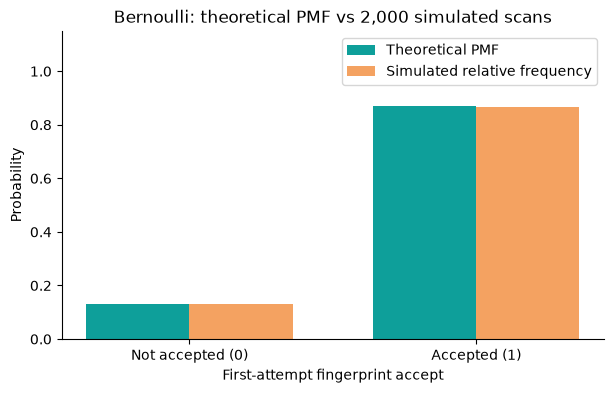

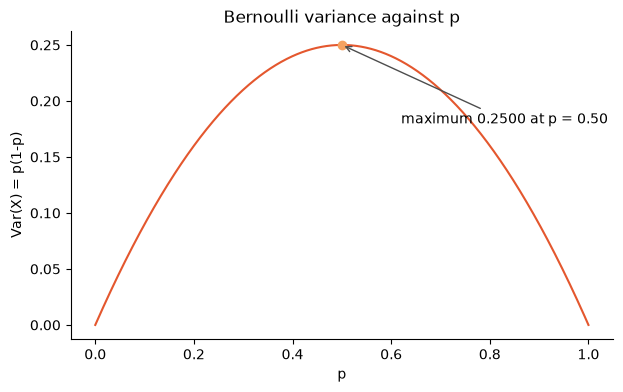

In [3]:
# Q2. Estimated Bernoulli p, simulation, and the variance curve
p = 1740 / 2000
n_scans = 2000
x = np.array([0, 1])
pmf = stats.bernoulli.pmf(x, p)

sample = stats.bernoulli.rvs(p, size=n_scans, random_state=42)
sim_p = sample.mean()
sim_freq = np.array([(sample == 0).mean(), (sample == 1).mean()])

print(f"theoretical p = {p:.4f}")
print(f"simulated proportion of successes = {sim_p:.4f}")
print(f"scipy mean = {stats.bernoulli.mean(p):.4f}    hand = 0.8700")
print(f"scipy var  = {stats.bernoulli.var(p):.4f}    hand = 0.1131")

width = 0.36
fig, ax = plt.subplots()
ax.bar(x - width / 2, pmf, width, color=DISCRETE_COLOR, label="Theoretical PMF")
ax.bar(x + width / 2, sim_freq, width, color=HIGHLIGHT_COLOR, label="Simulated relative frequency")
ax.set_xticks(x, ["Not accepted (0)", "Accepted (1)"])
ax.set_xlabel("First-attempt fingerprint accept")
ax.set_ylabel("Probability")
ax.set_title("Bernoulli: theoretical PMF vs 2,000 simulated scans")
ax.set_ylim(0, 1.15)
ax.legend()
plt.show()

p_grid = np.linspace(0, 1, 1001)
var_grid = p_grid * (1 - p_grid)
fig, ax = plt.subplots()
ax.plot(p_grid, var_grid, color=CONTINUOUS_COLOR)
ax.scatter([0.5], [0.25], color=HIGHLIGHT_COLOR, zorder=3)
ax.annotate(
    "maximum 0.2500 at p = 0.50",
    xy=(0.5, 0.25),
    xytext=(0.62, 0.18),
    arrowprops={"arrowstyle": "->", "color": "0.3"},
)
ax.set_xlabel("p")
ax.set_ylabel("Var(X) = p(1-p)")
ax.set_title("Bernoulli variance against p")
plt.show()


---
# Part B — Binomial distribution
*Recall:* $P(X=k) = \binom{n}{k}p^k(1-p)^{n-k}$, $\;E[X]=np$, $\;Var(X)=np(1-p)$.

## Q3. Guessing a multiple-choice quiz &nbsp;&nbsp;<sub>[5 marks] — *straightforward*</sub>

> 📝 An online quiz has **12 multiple-choice questions**, each with **4 options** and exactly one correct answer. A student who has not studied guesses every answer at random. Let $X$ = number of questions answered correctly.
>
> **(a)** State $n$ and $p$, check that the **BINS** conditions hold, and compute $P(X=5)$ **by hand**, showing the value of $\binom{12}{5}$.
> **(b)** Find the mean and the variance of $X$.
> **(c)** Write Python code that:
> - plots the PMF as a bar chart for $k = 0$ to $12$ in `DISCRETE_COLOR`,
>

#### Written answer (a) and (b)

**(a)** Each question has 4 options and one correct answer, and the student guesses, so

$$n = 12, \qquad p = \frac{1}{4} = 0.25$$

BINS holds:

| Condition | Check |
|---|---|
| Binary | Each answer is correct or not correct |
| Independent | One guess does not change the next |
| Number of trials fixed | The quiz has 12 questions |
| Same probability | $p = 0.25$ on every question |

$$\binom{12}{5} = \frac{12 \times 11 \times 10 \times 9 \times 8}{5 \times 4 \times 3 \times 2 \times 1} = \frac{95040}{120} = 792$$

$$P(X=5) = 792 \times (0.25)^5 \times (0.75)^7$$

$(0.25)^5 = 0.0009765625$ and $(0.75)^7 = 0.1334838867$. Their product is $0.0001303554$. Times 792:

$$P(X=5) = 0.1032$$

**(b)**

$$E[X] = np = 12 \times 0.25 = 3$$

$$Var(X) = np(1-p) = 3 \times 0.75 = 2.25$$


C(12, 5) = 792
P(X=5) = 0.1032
mean = 3.0000    variance = 2.2500


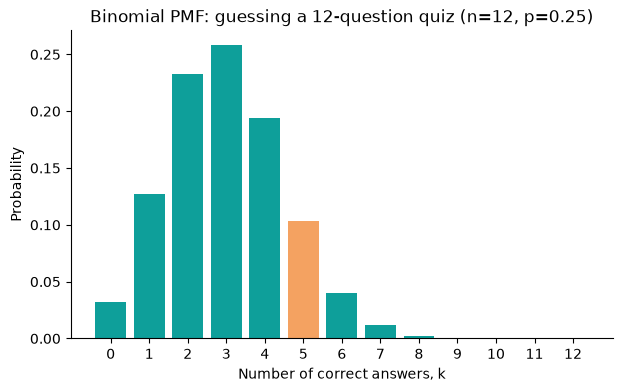

In [4]:
# Q3. Binomial PMF for 12 guessed MCQ answers
n, p = 12, 0.25
k = np.arange(0, n + 1)
pmf = stats.binom.pmf(k, n, p)
colors = [HIGHLIGHT_COLOR if ki == 5 else DISCRETE_COLOR for ki in k]

print(f"C(12, 5) = {comb(12, 5)}")
print(f"P(X=5) = {stats.binom.pmf(5, n, p):.4f}")
print(f"mean = {stats.binom.mean(n, p):.4f}    variance = {stats.binom.var(n, p):.4f}")

fig, ax = plt.subplots()
ax.bar(k, pmf, color=colors)
ax.set_xticks(k)
ax.set_xlabel("Number of correct answers, k")
ax.set_ylabel("Probability")
ax.set_title("Binomial PMF: guessing a 12-question quiz (n=12, p=0.25)")
plt.show()


#### ✍️ Written answer (a), (b) and (d) — *type your hand calculation below*

> 
> 
> 
> 
> 


---
# Part C — Poisson distribution
*Recall:* $P(X=k) = \dfrac{\lambda^k e^{-\lambda}}{k!}$, $\;E[X]=Var(X)=\lambda$.

## Q5. Help-desk emails &nbsp;&nbsp;<sub>[5 marks] — *straightforward*</sub>

> 📧 The IT help-desk of a college receives on average **3 emails per hour**. Let $X$ = number of emails received in one hour.
>
> **(a)** Compute $P(X = 0)$ and $P(X = 2)$ **by hand**, showing the substitution into the formula ($e^{-3} \approx 0.0498$).
> **(b)** State the mean and the variance, and explain in one line what is special about them for a Poisson distribution.
> **(c)** Write Python code that:
> - plots the PMF as a bar chart for $k = 0$ to $12$ in `DISCRETE_COLOR`,
> - prints $P(X=0)$, $P(X=2)$ and $P(X \le 5)$,
> - prints the smallest value of $k$ for which $P(X \le k) \ge 0.95$ (use `.ppf` or a loop).

#### Written answer (a) and (b)

**(a)** The mean rate is $\lambda = 3$ emails per hour. Using the given value $e^{-3} \approx 0.0498$:

$$P(X=0) = \frac{3^{0} e^{-3}}{0!} = 0.0498$$

$$P(X=2) = \frac{3^{2} \times 0.0498}{2!} = \frac{0.4482}{2} = 0.2241$$

`scipy` uses the full value of $e^{-3}$, so the code prints $P(X=2) = 0.2240$. The hand result above follows the $0.0498$ given in the question.

**(b)** For a Poisson distribution the mean and the variance are the same number:

$$E[X] = Var(X) = \lambda = 3$$


P(X=0) = 0.0498
P(X=2) = 0.2240
P(X<=5) = 0.9161
smallest k with P(X<=k) >= 0.95 is k = 6
check: CDF(5) = 0.9161    CDF(6) = 0.9665
mean = 3.0000    variance = 3.0000


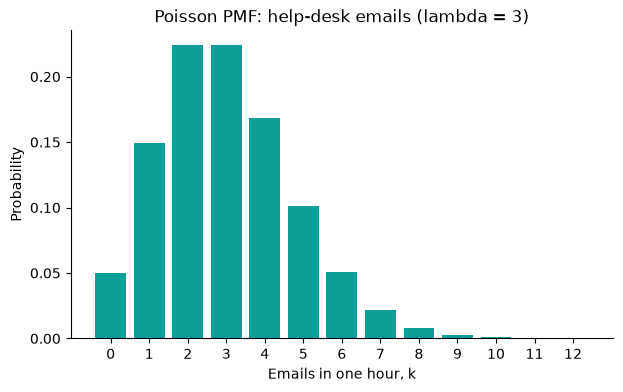

In [5]:
# Q5. Poisson PMF for help-desk emails, lambda = 3
lam = 3
k = np.arange(0, 13)
pmf = stats.poisson.pmf(k, lam)
k_95 = int(stats.poisson.ppf(0.95, lam))

print(f"P(X=0) = {stats.poisson.pmf(0, lam):.4f}")
print(f"P(X=2) = {stats.poisson.pmf(2, lam):.4f}")
print(f"P(X<=5) = {stats.poisson.cdf(5, lam):.4f}")
print(f"smallest k with P(X<=k) >= 0.95 is k = {k_95}")
print(f"check: CDF({k_95 - 1}) = {stats.poisson.cdf(k_95 - 1, lam):.4f}    CDF({k_95}) = {stats.poisson.cdf(k_95, lam):.4f}")
print(f"mean = {stats.poisson.mean(lam):.4f}    variance = {stats.poisson.var(lam):.4f}")

fig, ax = plt.subplots()
ax.bar(k, pmf, color=DISCRETE_COLOR)
ax.set_xticks(k)
ax.set_xlabel("Emails in one hour, k")
ax.set_ylabel("Probability")
ax.set_title("Poisson PMF: help-desk emails (lambda = 3)")
plt.show()


## Q6. Server errors over a night shift &nbsp;&nbsp;<sub>[5 marks] — *harder*</sub>

> 🖥️ A web server logs errors at an average rate of **1.5 errors per hour**. The night shift runs from 10 pm to 6 am, i.e. **8 hours**.
>
> **(a)** Find the value of $\lambda$ for the **whole 8-hour shift**, and compute by hand the probability of a **clean shift** (zero errors in the 8 hours).
> **(b)** State the mean and variance for the 8-hour window. The on-call engineer is paged if **more than 18 errors** occur in the shift — write the expression for that probability and name the `scipy` function that gives it directly.
> **(c)** Write Python code that:
> - creates **two subplots side by side** — the PMF for the 1-hour window ($\lambda = 1.5$) and the PMF for the 8-hour window — each with its own sensible range of $k$, title and labels,


#### Written answer (a) and (b)

**(a)** Scale the hourly rate across the 8-hour shift:

$$\lambda_{8} = 1.5 \times 8 = 12$$

A clean shift is $X = 0$:

$$P(X=0) = \frac{12^{0} e^{-12}}{0!} = e^{-12} = 6.1442 \times 10^{-6}$$

Rounded to four decimal places this is $0.0000$, so the value is reported in scientific form.

**(b)** Over the shift, $E[X] = Var(X) = 12$.

The engineer is paged when $X > 18$:

$$P(X > 18) = 1 - P(X \le 18)$$

`stats.poisson.sf(18, 12)` returns that probability directly. It equals $0.0374$.


lambda for 8 hours = 12.0
P(clean shift) = P(X=0) = 6.144212e-06
P(X>18) = 0.0374    via stats.poisson.sf(18, 12)
mean = var = 12.0


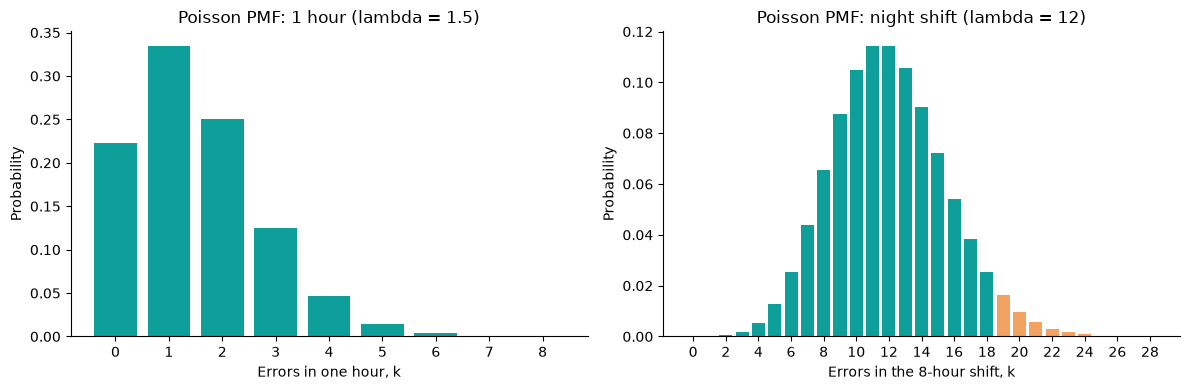

In [6]:
# Q6. Poisson PMF for 1 hour and for the 8-hour night shift
lam_hour = 1.5
lam_shift = 1.5 * 8
k_hour = np.arange(0, 9)
k_shift = np.arange(0, 29)
pmf_hour = stats.poisson.pmf(k_hour, lam_hour)
pmf_shift = stats.poisson.pmf(k_shift, lam_shift)
shift_colors = [HIGHLIGHT_COLOR if ki > 18 else DISCRETE_COLOR for ki in k_shift]

print(f"lambda for 8 hours = {lam_shift:.1f}")
print(f"P(clean shift) = P(X=0) = {stats.poisson.pmf(0, lam_shift):.6e}")
print(f"P(X>18) = {stats.poisson.sf(18, lam_shift):.4f}    via stats.poisson.sf(18, 12)")
print(f"mean = var = {stats.poisson.mean(lam_shift):.1f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(k_hour, pmf_hour, color=DISCRETE_COLOR)
axes[0].set_xticks(k_hour)
axes[0].set_xlabel("Errors in one hour, k")
axes[0].set_ylabel("Probability")
axes[0].set_title("Poisson PMF: 1 hour (lambda = 1.5)")

axes[1].bar(k_shift, pmf_shift, color=shift_colors)
axes[1].set_xticks(k_shift[::2])
axes[1].set_xlabel("Errors in the 8-hour shift, k")
axes[1].set_ylabel("Probability")
axes[1].set_title("Poisson PMF: night shift (lambda = 12)")
fig.tight_layout()
plt.show()


---
# Part D — Normal distribution
*Recall:* $f(x)=\dfrac{1}{\sigma\sqrt{2\pi}}e^{-(x-\mu)^2/2\sigma^2}$, $\;Z=\dfrac{X-\mu}{\sigma}$, $\;E[X]=\mu$, $\;Var(X)=\sigma^2$.

## Q7. Battery life of a phone &nbsp;&nbsp;<sub>[5 marks] — *straightforward*</sub>

> 🔋 The battery life of a phone model is normally distributed with a mean of **18 hours** and a standard deviation of **1.5 hours**. Let $X$ = battery life of a randomly chosen phone.
>
> **(a)** Compute the **Z-score** for a battery life of 15 hours and say in words what that Z-score means.
> **(b)** Using the 68–95–99.7 rule, state the interval of battery lives that contains about **95%** of the phones. Show how you obtained it.
> **(c)** Write Python code that:
> - generates 400 equally spaced values of $x$ over $\mu \pm 4\sigma$ and computes the PDF,
> - plots the curve in `CONTINUOUS_COLOR` with a title and axis labels,
.

#### Written answer (a) and (b)

**(a)**

$$Z = \frac{15 - 18}{1.5} = \frac{-3}{1.5} = -2$$

A battery life of 15 hours is 2 standard deviations below the mean of 18 hours.

**(b)** The 68-95-99.7 rule puts about 95% of the values inside $\mu \pm 2\sigma$:

$$18 \pm 2(1.5) = 18 \pm 3$$

so the interval is **15 hours to 21 hours**.


Z for 15 hours = -2.0000
95% interval from the rule: 15.0 to 21.0 hours
scipy mean = 18.0000    variance = 2.2500


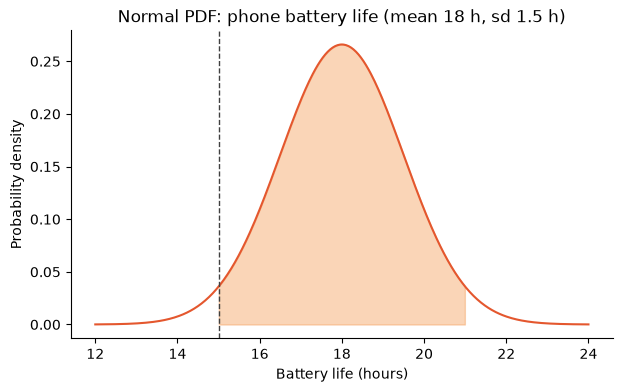

In [7]:
# Q7. Normal PDF of phone battery life
mu, sigma = 18, 1.5
x = np.linspace(mu - 4 * sigma, mu + 4 * sigma, 400)
pdf = stats.norm.pdf(x, loc=mu, scale=sigma)
low, high = mu - 2 * sigma, mu + 2 * sigma

print(f"Z for 15 hours = {(15 - mu) / sigma:.4f}")
print(f"95% interval from the rule: {low:.1f} to {high:.1f} hours")
print(f"scipy mean = {stats.norm.mean(loc=mu, scale=sigma):.4f}    variance = {stats.norm.var(loc=mu, scale=sigma):.4f}")

fig, ax = plt.subplots()
ax.plot(x, pdf, color=CONTINUOUS_COLOR)
ax.fill_between(x, pdf, where=(x >= low) & (x <= high), color=HIGHLIGHT_COLOR, alpha=0.45)
ax.axvline(15, color="0.25", linestyle="--", linewidth=1)
ax.set_xlabel("Battery life (hours)")
ax.set_ylabel("Probability density")
ax.set_title("Normal PDF: phone battery life (mean 18 h, sd 1.5 h)")
plt.show()


## Q8. Calibrating a coffee machine &nbsp;&nbsp;<sub>[5 marks] — *harder*</sub>

> ☕ A vending machine fills cups with coffee. The fill volume is normally distributed with a mean of **200 ml**, but the standard deviation is **not known**. The service log shows that **2.5% of cups overflow**, which happens whenever the fill exceeds **210 ml**.
>
> **(a)** Using the standard normal value $z_{0.975} \approx 1.96$, find the standard deviation $\sigma$ of the fill volume. Show the working.
> **(b)** With that $\sigma$, find the volume below which only **1%** of cups fall (the 1st percentile), and state which `scipy` function gives it. A customer complains if the cup holds less than **190 ml** — write the expression for that probability.
> **(c)** Write Python code that:
> - computes $\sigma$ using `stats.norm.ppf` rather than the rounded 1.96,
> - plots the PDF over a sensible range in `CONTINUOUS_COLOR`,



#### Written answer (a) and (b)

**(a)** Overflow of the top 2.5% means $P(X > 210) = 0.025$, so $P(X \le 210) = 0.975$ and $z_{0.975} \approx 1.96$.

$$1.96 = \frac{210 - 200}{\sigma} \implies \sigma = \frac{10}{1.96} = 5.1020 \text{ ml}$$

**(b)** The 1st percentile is the volume $x$ with $P(X \le x) = 0.01$. The matching standard-normal value is $z_{0.01} \approx -2.3263$, and `stats.norm.ppf(0.01, loc=200, scale=sigma)` returns $x$ directly.

$$x = 200 + (-2.3263)(5.1020) = 188.1307 \text{ ml}$$

A complaint is a fill under 190 ml:

$$P(X < 190) = \texttt{stats.norm.cdf}(190,\ 200,\ \sigma) \approx 0.0250$$


z_0.975 from scipy = 1.9600
sigma = 5.1021 ml    (hand value using 1.96 is 5.1020 ml)
1st percentile = 188.1307 ml    via stats.norm.ppf
P(X < 190) = 0.0250


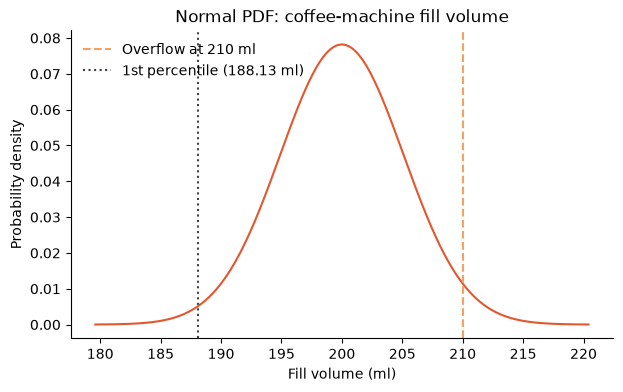

In [8]:
# Q8. Normal fill volume. sigma from the 97.5th percentile, not from the rounded 1.96
mu = 200
z_975 = stats.norm.ppf(0.975)
sigma = (210 - mu) / z_975
x = np.linspace(mu - 4 * sigma, mu + 4 * sigma, 400)
pdf = stats.norm.pdf(x, loc=mu, scale=sigma)
pct_01 = stats.norm.ppf(0.01, loc=mu, scale=sigma)
p_complaint = stats.norm.cdf(190, loc=mu, scale=sigma)

print(f"z_0.975 from scipy = {z_975:.4f}")
print(f"sigma = {sigma:.4f} ml    (hand value using 1.96 is 5.1020 ml)")
print(f"1st percentile = {pct_01:.4f} ml    via stats.norm.ppf")
print(f"P(X < 190) = {p_complaint:.4f}")

fig, ax = plt.subplots()
ax.plot(x, pdf, color=CONTINUOUS_COLOR)
ax.axvline(210, color=HIGHLIGHT_COLOR, linestyle="--", label="Overflow at 210 ml")
ax.axvline(pct_01, color="0.25", linestyle=":", label=f"1st percentile ({pct_01:.2f} ml)")
ax.set_xlabel("Fill volume (ml)")
ax.set_ylabel("Probability density")
ax.set_title("Normal PDF: coffee-machine fill volume")
ax.legend(loc="upper left", frameon=False)
plt.show()


---
# Part E — Uniform distribution
*Recall:* $f(x)=\dfrac{1}{b-a}$ for $a \le x \le b$, $\;P(c \le X \le d)=\dfrac{d-c}{b-a}$, $\;E[X]=\dfrac{a+b}{2}$, $\;Var(X)=\dfrac{(b-a)^2}{12}$.

⚠️ **Note on `scipy`:** for a uniform distribution on $[a, b]$ you must use `loc=a` and `scale=b-a`, **not** `loc=a, scale=b`.

## Q9. Waiting for the campus shuttle &nbsp;&nbsp;<sub>[5 marks] — *straightforward*</sub>

> 🚌 The campus shuttle leaves the gate exactly every **15 minutes**. A student walks up to the stop at a completely random moment, so her waiting time $X$ is uniformly distributed between **0 and 15 minutes**.
>

> **(a)** Find the mean waiting time and the variance, showing the substitution.
> **(b)** Write Python code that:
> - plots the PDF as a flat line/rectangle over $[0, 15]$ in `CONTINUOUS_COLOR` (extend the x-axis a little beyond the range so the flat top is clear),


#### Written answer (a)

The wait is uniform on $[0, 15]$, so $a = 0$ and $b = 15$.

$$E[X] = \frac{a+b}{2} = \frac{0+15}{2} = 7.5 \text{ minutes}$$

$$Var(X) = \frac{(b-a)^2}{12} = \frac{15^2}{12} = \frac{225}{12} = 18.75$$

Part (b) is the plot in the next cell. The PDF height on $[0, 15]$ is $1/15 \approx 0.0667$.


PDF height = 0.0667
scipy mean = 7.5000    hand = 7.5000
scipy var  = 18.7500    hand = 18.7500


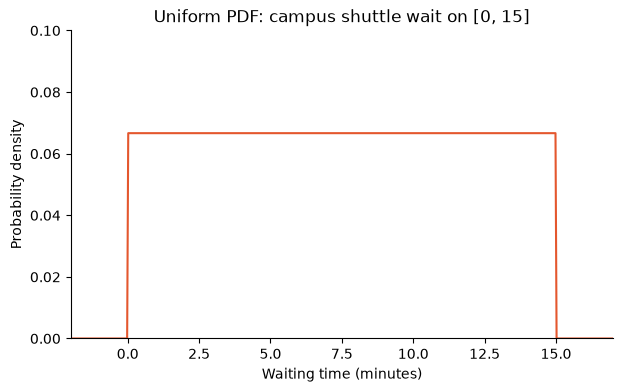

In [9]:
# Q9. Uniform PDF of shuttle waiting time on [0, 15]
a, b = 0, 15
x = np.linspace(a - 2, b + 2, 500)
pdf = stats.uniform.pdf(x, loc=a, scale=b - a)

print(f"PDF height = {1 / (b - a):.4f}")
print(f"scipy mean = {stats.uniform.mean(loc=a, scale=b - a):.4f}    hand = 7.5000")
print(f"scipy var  = {stats.uniform.var(loc=a, scale=b - a):.4f}    hand = 18.7500")

fig, ax = plt.subplots()
ax.plot(x, pdf, color=CONTINUOUS_COLOR)
ax.set_xlim(a - 2, b + 2)
ax.set_ylim(0, 0.10)
ax.set_xlabel("Waiting time (minutes)")
ax.set_ylabel("Probability density")
ax.set_title("Uniform PDF: campus shuttle wait on [0, 15]")
plt.show()


---
### Note on the issued notebook

The file issued for this assignment stops in the middle of Q3(c), Q6(c), Q7(c), Q8(c) and Q9(b). It has no question text for Q4 or Q10. The cells above answer every part that is present. Probabilities are rounded to 4 decimal places. Where that rounding would print 0.0000 (the clean night shift), the fuller value is shown as well.

### What the plots show

| Question | Distribution | Result used in the plot |
|---|---|---|
| Q1 | Bernoulli, $p=0.92$ | $P(X=1)=0.9200$, variance $0.0736$ |
| Q2 | Bernoulli, $\hat p=0.87$ | Variance is largest at $p=0.5$, value $0.25$ |
| Q3 | Binomial, $n=12$, $p=0.25$ | $P(X=5)=0.1032$, mean $3$, variance $2.25$ |
| Q5 | Poisson, $\lambda=3$ | $P(X\le 5)=0.9161$; smallest $k$ with CDF at least 0.95 is $k=6$ |
| Q6 | Poisson, $\lambda=12$ for 8 hours | $P(X>18)=0.0374$ |
| Q7 | Normal, $\mu=18$, $\sigma=1.5$ | 95% rule interval is 15 to 21 hours |
| Q8 | Normal, $\mu=200$ | $\sigma \approx 5.1021$ ml from `norm.ppf`; $P(X<190)\approx 0.0250$ |
| Q9 | Uniform on $[0,15]$ | Mean $7.5$ minutes, variance $18.75$ |
